# ML4G Project 1: Getting Started

This notebook shows you how to **load the competition data** on Kaggle and how to **write a correctly formatted submission file**. The submission it produces is a constant placeholder, which scores 0. Your solution goes in the marked section.

**Before you start:** you may need to add the competition dataset to this notebook (right panel → *Add Input*), then run all cells.

## 1. Setup

In [1]:
import os
import glob
import zipfile

import numpy as np
import pandas as pd

## 2. Locate the data

On Kaggle, attached datasets are mounted read-only under `/kaggle/input/`. Locally, the notebook reads the competition `.zip` files from `data/input/`. In both cases the cell below extracts any archives into `<WORK_DIR>/extracted` (`data/working/extracted` locally).

In [2]:
ON_KAGGLE = os.path.isdir("/kaggle/input")

# Locally, put the competition .zip files in data/input/ (relative to this notebook).
INPUT_ROOT = "/kaggle/input" if ON_KAGGLE else "data/input"
WORK_DIR = "/kaggle/working" if ON_KAGGLE else "data/working"
EXTRACT_DIR = os.path.join(WORK_DIR, "extracted")
os.makedirs(WORK_DIR, exist_ok=True)

for zp in glob.glob(os.path.join(INPUT_ROOT, "**", "*.zip"), recursive=True):
    target = os.path.join(EXTRACT_DIR, os.path.splitext(os.path.basename(zp))[0])
    if not os.path.isdir(target):
        with zipfile.ZipFile(zp) as zf:
            zf.extractall(target)

# Skip macOS zip metadata (__MACOSX/._*), which would otherwise match the track patterns.
ALL_FILES = sorted(
    p for root in [INPUT_ROOT, EXTRACT_DIR]
    for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
    if os.path.isfile(p) and not p.endswith(".zip") and "__MACOSX" not in p
)
print(f"{len(ALL_FILES)} files found")
for p in ALL_FILES:
    print(p)

52 files found
data/working/extracted/CAGE-train/CAGE-train/X1_train_info.tsv
data/working/extracted/CAGE-train/CAGE-train/X1_train_y.tsv
data/working/extracted/CAGE-train/CAGE-train/X1_val_info.tsv
data/working/extracted/CAGE-train/CAGE-train/X1_val_y.tsv
data/working/extracted/CAGE-train/CAGE-train/X2_train_info.tsv
data/working/extracted/CAGE-train/CAGE-train/X2_train_y.tsv
data/working/extracted/CAGE-train/CAGE-train/X2_val_info.tsv
data/working/extracted/CAGE-train/CAGE-train/X2_val_y.tsv
data/working/extracted/CAGE-train/CAGE-train/X3_test_info.tsv
data/working/extracted/DNase-bed/X1.bed
data/working/extracted/DNase-bed/X2.bed
data/working/extracted/DNase-bed/X3.bed
data/working/extracted/DNase-bigwig/X1.bw
data/working/extracted/DNase-bigwig/X2.bw
data/working/extracted/DNase-bigwig/X3.bigwig
data/working/extracted/H3K27ac-bed/X1.bed
data/working/extracted/H3K27ac-bed/X2.bed
data/working/extracted/H3K27ac-bed/X3.bed
data/working/extracted/H3K27ac-bigwig/X1.bigwig
data/working/ex

In [3]:
def find_file(name):
    # Path of the unique file whose name is `name`.
    hits = [p for p in ALL_FILES if os.path.basename(p) == name]
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected exactly 1 file named {name}, found {len(hits)}: {hits}")
    return hits[0]


def find_track(mark, cell_line, kind):
    # Path of a chromatin track. kind: 'bed' (narrowPeak peaks) or 'bigwig' (continuous signal).
    exts = (".bed", ".bed.gz", ".narrowpeak", ".narrowpeak.gz") if kind == "bed" else (".bw", ".bigwig")
    hits = [
        p for p in ALL_FILES
        if mark in p and cell_line in os.path.basename(p) and p.lower().endswith(exts)
    ]
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected exactly 1 {kind} file for {mark}/{cell_line}, found {len(hits)}: {hits}")
    return hits[0]

## 3. Gene information and targets

Each cell line and split has an `*_info.tsv` file with gene coordinates and, for X1 and X2, a `*_y.tsv` file with CAGE expression. The X3 test genes come without targets.

| Split | Chromosomes | Cell lines |
|---|---|---|
| train (set A) | chr2–13, chr15–18, chr20–22 | X1, X2 |
| val (set B) | chr14, chr19 | X1, X2 |
| test (set C) | chr1 | X3 |

In [4]:
def load_split(cell_line, split):
    info = pd.read_csv(find_file(f"{cell_line}_{split}_info.tsv"), sep="\t")
    if split == "test":
        return info
    y = pd.read_csv(find_file(f"{cell_line}_{split}_y.tsv"), sep="\t")
    return info.merge(y, on="gene_name", how="inner", validate="one_to_one")

data = {
    ("X1", "train"): load_split("X1", "train"),
    ("X1", "val"):   load_split("X1", "val"),
    ("X2", "train"): load_split("X2", "train"),
    ("X2", "val"):   load_split("X2", "val"),
    ("X3", "test"):  load_split("X3", "test"),
}

for key, df in data.items():
    print(key, df.shape)
data[("X1", "train")].head()

('X1', 'train') (14310, 8)
('X1', 'val') (1974, 8)
('X2', 'train') (14310, 8)
('X2', 'val') (1974, 8)
('X3', 'test') (1984, 7)


,gene_name,chr,gene_start,gene_end,TSS_start,TSS_end,strand,gex
0,SLC20A1,chr2,112645939,112663825,112658362,112658412,+,0.000000
1,C11orf58,chr11,16613132,16758340,16738643,16738693,+,2239.103328
2,ZSCAN9,chr6,28224886,28233487,28225263,28225313,+,19.798064
3,CD19,chr16,28931965,28939342,28931956,28932006,+,411.530623
4,TMEM123,chr11,102396332,102470384,102452789,102452839,-,34.214129


## 4. Chromatin tracks

Each assay (DNase, H3K4me3, H3K4me1, H3K27ac, H3K36me3, H3K27me3, H3K9me3) comes as **BED narrowPeak** (called peaks) and **bigWig** (continuous signal), one file per cell line.

narrowPeak files have 10 tab-separated columns without a header. Format specification: https://genome.ucsc.edu/FAQ/FAQformat.html#format12

In [5]:
NARROWPEAK_COLS = ["chrom", "chromStart", "chromEnd", "name", "score", "strand",
                   "signalValue", "pValue", "qValue", "peak"]

def load_peaks(mark, cell_line):
    return pd.read_csv(find_track(mark, cell_line, "bed"), sep="\t", header=None,
                       names=NARROWPEAK_COLS, usecols=range(10), comment="#")

peaks = load_peaks("DNase", "X1")
print(peaks.shape)
peaks.head()

(56452, 10)


,chrom,chromStart,chromEnd,name,score,strand,signalValue,pValue,qValue,peak
0,chr1,181405,181555,.,0,.,12.379543,-1,-1,75
1,chr1,267990,268140,.,0,.,12.379543,-1,-1,75
2,chr1,629160,629310,.,0,.,22.263896,-1,-1,75
3,chr1,629494,629644,.,0,.,10.732151,-1,-1,75
4,chr1,629870,630020,.,0,.,3603.694491,-1,-1,75


Reading bigWig files requires `pyBigWig`, which needs *Internet on* in the notebook settings (phone-verified Kaggle account):

In [8]:
!pip install -q pyBigWig
import pyBigWig
#
bw = pyBigWig.open(find_track("DNase", "X1", "bigwig"))
print(bw.chroms("chr2"))
print(bw.stats("chr2", 1_000_000, 1_002_000, type="mean"))   # mean signal in a 2 kb window

242193529
[0.04259009861318022]


## 5. Your solution

Build your features and model here. Train and validate on X1 and X2, then predict the expression of the X3 test genes.

The submission is scored with **Spearman's rank correlation**, so only the order of your predictions matters. You can compute it locally with `scipy.stats.spearmanr` on your validation sets.

At the end of this section, `pred` must be a numeric array with one value per row of `test_genes`, in the same order.

### Package 1.1 (Pre-processing)

In [11]:
import pyBigWig
from scipy.stats import spearmanr

MARKS = ["DNase", "H3K4me3", "H3K4me1", "H3K27ac", "H3K36me3", "H3K27me3", "H3K9me3"]

## Mark the TSS by the mid-point
for df in data.values():
    df["tss"] = (df["TSS_start"] + df["TSS_end"]) // 2

for (cell, split), df in data.items():
    assert df["gene_name"].is_unique, f"duplicate genes in {cell} {split}"
    width = (df["TSS_end"] - df["TSS_start"]).value_counts()
    print(cell, split, len(df), "genes | chroms:", sorted(df["chr"].unique())[:3], "... |",
          "TSS widths:", width.to_dict(), "| strands:", df["strand"].value_counts().to_dict())

X1 train 14310 genes | chroms: ['chr10', 'chr11', 'chr12'] ... | TSS widths: {50: 13406, 48: 44, 43: 43, 45: 41, 37: 36, 30: 35, 47: 34, 35: 34, 33: 34, 46: 33, 39: 32, 41: 30, 42: 30, 44: 29, 36: 28, 38: 28, 28: 27, 31: 26, 40: 25, 34: 25, 49: 24, 27: 24, 32: 23, 29: 22, 25: 20, 26: 18, 23: 17, 21: 16, 17: 14, 24: 14, 22: 11, 14: 10, 19: 10, 15: 10, 20: 8, 18: 8, 4: 6, 8: 6, 16: 6, 7: 5, 10: 5, 9: 3, 6: 3, 11: 2, 13: 2, 12: 1, 5: 1, 3: 1} | strands: {'+': 7210, '-': 7100}
X1 val 1974 genes | chroms: ['chr14', 'chr19'] ... | TSS widths: {50: 1805, 47: 12, 45: 11, 33: 10, 46: 9, 42: 8, 44: 7, 43: 7, 34: 7, 38: 6, 24: 6, 32: 6, 37: 5, 25: 5, 36: 5, 48: 5, 23: 4, 35: 4, 41: 4, 22: 4, 19: 4, 39: 4, 40: 4, 49: 3, 21: 3, 15: 2, 27: 2, 4: 2, 18: 2, 28: 2, 29: 2, 31: 2, 6: 2, 13: 2, 20: 2, 26: 1, 5: 1, 2: 1, 30: 1, 17: 1, 3: 1} | strands: {'+': 1004, '-': 970}
X2 train 14310 genes | chroms: ['chr10', 'chr11', 'chr12'] ... | TSS widths: {50: 13404, 48: 48, 45: 47, 43: 42, 37: 38, 47: 36, 35: 33

        count       mean         std  min  25%       50%       75%  \
cell                                                                 
X1    16284.0  51.802523  319.126838  0.0  0.0  0.000000  8.169104   
X2    16284.0  52.919741  331.844136  0.0  0.0  0.096071  8.262099   

               max  
cell                
X1    19519.833527  
X2    19512.484272  
fraction exactly zero: {'X1': 0.58, 'X2': 0.496}
fraction < 1: {'X1': 0.635, 'X2': 0.642}


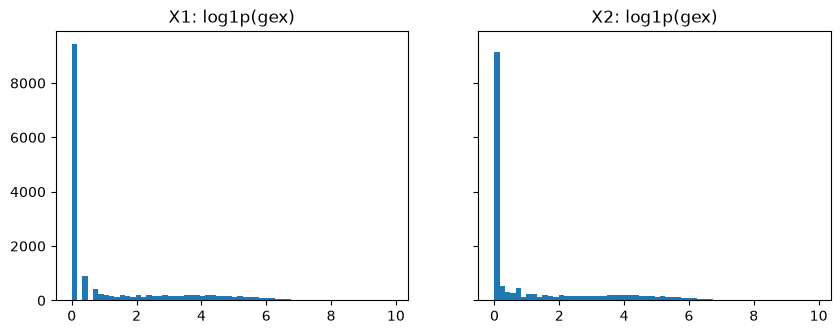

In [14]:
lab = pd.concat([df.assign(cell=c, split=s) for (c, s), df in data.items() if s != "test"])

print(lab.groupby("cell")["gex"].describe())
print("fraction exactly zero:", (lab["gex"] == 0).groupby(lab["cell"]).mean().round(3).to_dict())
print("fraction < 1:", (lab["gex"] < 1).groupby(lab["cell"]).mean().round(3).to_dict())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, cell in zip(axes, ["X1", "X2"]):
    ax.hist(np.log1p(lab.loc[lab.cell == cell, "gex"]), bins=60)
    ax.set_title(f"{cell}: log1p(gex)")
plt.show()


In [15]:
tss_by_cell = {
    c: pd.concat([data[(c, s)] for s in ("train", "val")]).set_index("gene_name")["tss"]
    for c in ("X1", "X2")
}
common = tss_by_cell["X1"].index.intersection(tss_by_cell["X2"].index)
diff = (tss_by_cell["X1"][common] - tss_by_cell["X2"][common]).abs()

print(f"X1 genes: {len(tss_by_cell['X1'])}, X2 genes: {len(tss_by_cell['X2'])}, shared: {len(common)}")
print(f"TSS differs for {(diff > 0).mean():.1%} of shared genes")
print(diff[diff > 0].describe())


X1 genes: 16284, X2 genes: 16284, shared: 16284
TSS differs for 8.9% of shared genes
count    1.445000e+03
mean     9.904988e+03
std      5.548420e+04
min      1.000000e+00
25%      1.300000e+01
50%      2.800000e+01
75%      6.100000e+01
max      1.098020e+06
Name: tss, dtype: float64


In [16]:
for cell in ("X1", "X2", "X3"):
    bw = pyBigWig.open(find_track("H3K4me3", cell, "bigwig"))
    print(cell, "chroms:", len(bw.chroms()), "| chr1 len:", bw.chroms("chr1"),
          "| header:", {k: round(v, 2) for k, v in bw.header().items() if k in ("minVal", "maxVal", "sumData")})
    bw.close()

peaks = load_peaks("H3K4me3", "X1")
print(peaks.describe()[["chromEnd", "signalValue", "peak"]])
print("peak widths:", (peaks.chromEnd - peaks.chromStart).describe().round(0).to_dict())


X1 chroms: 152 | chr1 len: 248956422 | header: {'minVal': 0, 'maxVal': 261, 'sumData': 1378128638}
X2 chroms: 138 | chr1 len: 248956422 | header: {'minVal': 0, 'maxVal': 114, 'sumData': 1238378140}
X3 chroms: 125 | chr1 len: 248956422 | header: {'minVal': 0, 'maxVal': 480, 'sumData': 1557486077}
           chromEnd   signalValue          peak
count  4.200200e+04  42002.000000  42002.000000
mean   7.556926e+07      8.149381    603.167992
std    5.587636e+07      4.591363    678.535776
min    2.068000e+03      1.426783      1.000000
25%    3.228666e+07      4.579046    185.000000
50%    6.354754e+07      6.370740    366.000000
75%    1.110245e+08     11.102477    755.000000
max    2.489074e+08     37.780053  13516.000000
peak widths: {'count': 42002.0, 'mean': 1213.0, 'std': 1112.0, 'min': 200.0, '25%': 479.0, '50%': 808.0, '75%': 1560.0, 'max': 13937.0}


In [9]:
test_genes = data[("X3", "test")]

# ============================== YOUR SOLUTION ==============================
#
#
#
#
# ===========================================================================

# Placeholder: constant prediction (scores 0). Replace with your model's output.
pred = np.zeros(len(test_genes))

## 6. Write the submission

The required format is a CSV with header `gene_name,gex_predicted` and exactly one row per gene in `X3_test_info.tsv`, **without an index column**. The checks below catch the most common mistakes before you spend one of your 10 submissions.

In [8]:
submission = pd.DataFrame({
    "gene_name": test_genes["gene_name"].to_numpy(),
    "gex_predicted": np.asarray(pred, dtype=float),
})

assert len(submission) == len(test_genes), "One prediction per test gene required"
assert submission["gene_name"].is_unique, "Duplicate gene names"
assert np.isfinite(submission["gex_predicted"]).all(), "Predictions contain NaN or inf"

out_path = os.path.join(WORK_DIR, "submission.csv")
submission.to_csv(out_path, index=False)   # index=False is essential
print(f"Saved {out_path}")
print(open(out_path).read()[:150])

Saved /kaggle/working/submission.csv
gene_name,gex_predicted
CAPN9,0.0
ILF2,0.0
ST6GALNAC5,0.0
MROH7-TTC4,0.0
AGO4,0.0
AKR1A1,0.0
LRRC8B,0.0
EFNA3,0.0
GSTM3,0.0
CRYBG2,0.0
CCDC24,0.0
ARHG


### How to submit

- **From this notebook:** click *Save Version* (Save & Run All). When it finishes, open the version's *Output* tab and click *Submit*. The competition must be attached as an input for the button to appear.
- **Manually:** download `submission.csv` from the *Output* panel and upload it on the competition's *Submit Prediction* page.

Every successful submission counts toward your team's limit of 10. Files rejected with a format error don't count.